# Patterns of behaviour and the structures behind them in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/04-patterns.ipynb)

A handful of shapes turn up again and again when you plot how a system changes over time: exponential growth, goal seeking, oscillation, S-shaped growth. Each one points to a particular kind of feedback structure. This notebook runs a molecule for each pattern, shows how the combined patterns come from loops taking turns to dominate, and ends with a short function that names the pattern in any time series, so you can test your eye against the numbers.

The ideas are taught in the app module [Patterns of behaviour and the structures behind them](https://waelrash1.github.io/loopbricks/#/learn/patterns).

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Three basic patterns, three structures

- **Exponential growth** comes from a dominant reinforcing loop: the stock feeds its own inflow. Molecule: `growth`.
- **Goal seeking** comes from a dominant balancing loop: the flow is driven by the gap between the stock and a goal. Molecule: `closegap`.
- **Oscillation** comes from a balancing loop with a delay in it: the correction keeps acting after the gap has closed. Molecule: `lowVisPipeline`, where a buyer orders to refill a shop's inventory but forgets the orders that are already on their way from a slow supplier.

growth:       100 -> 603, and the yearly increase keeps getting bigger
goal seeking: 20 -> 60.0, moving fastest at the start
oscillation:  60, peak 117.2 in week 16.4, then down to 91.9 in week 30.8


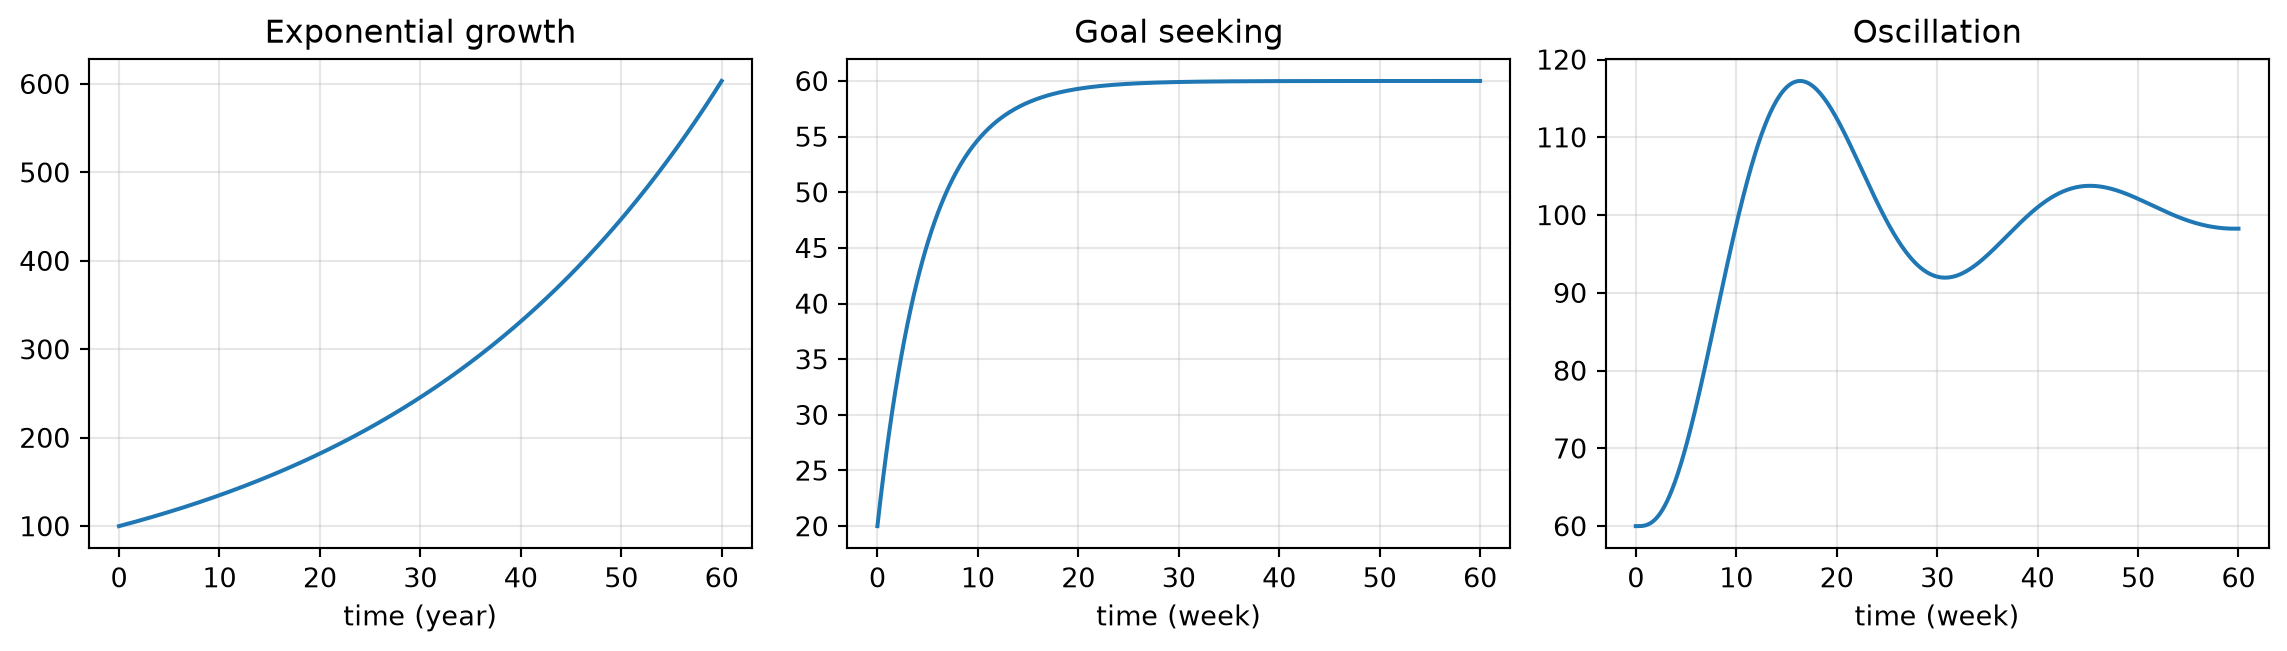

In [2]:
growth = lb.molecule("growth").run()["Population"]
goal = lb.molecule("closegap").run()["Actual"]
lv = lb.molecule("lowVisPipeline")
swing = lv.run(preset="Ignores the pipeline")["Inventory"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, series, title in zip(axes, (growth, goal, swing), ("Exponential growth", "Goal seeking", "Oscillation")):
    series.plot(ax=ax, title=title); ax.grid(alpha=0.3)
plt.tight_layout()

print(f"growth:       {growth.iloc[0]:.0f} -> {growth.iloc[-1]:.0f}, and the yearly increase keeps getting bigger")
print(f"goal seeking: {goal.iloc[0]:.0f} -> {goal.iloc[-1]:.1f}, moving fastest at the start")
print(f"oscillation:  {swing.iloc[0]:.0f}, peak {swing.max():.1f} in week {swing.idxmax()}, "
      f"then down to {swing.loc[25:40].min():.1f} in week {swing.loc[25:40].idxmin()}")

The three runs have the shapes their structures predict. Population grows six-fold in 60 years, faster every year. The goal-seeking stock covers most of its distance early and then creeps towards 60. The inventory overshoots its target of 100 to reach 117 in week 16, undershoots to 92 around week 31, and keeps swinging with smaller and smaller swings: the orders placed during the shortage keep arriving long after the shortage is over.

**Try it.** Run the `decay` molecule (a stock of 100 that drains at a rate of stock / 5 a year). Which of the three patterns is it, and what structure produces it? When is half the stock gone?

<details><summary>Show a worked answer</summary>

Goal seeking, with a goal of zero: the outflow is proportional to the stock, so it is a single balancing loop, and the stock falls fastest at the start. Half the stock is gone in year 3.5 (the exact half-life is 5 × ln 2 ≈ 3.47 years). The run shows 36.4 left after 5 years, 13.3 after 10, 4.8 after 15.
</details>

In [3]:
stock = lb.molecule("decay").run()["Stock"]
print("Half gone in year", stock.index[stock <= 50][0])
print(stock.loc[[5.0, 10.0, 15.0]].round(1))

Half gone in year 3.5
time (year)
5.0     36.4
10.0    13.3
15.0     4.8
Name: Stock, dtype: float64


## 2. Combined patterns: S-shaped growth

Real growth cannot go on for ever. In **Constrained Growth** (`logistic`) a population grows by 18% a year, but crowding deaths rise as it fills the carrying capacity of 200. Early on the reinforcing loop dominates and the curve looks exponential; later the balancing loop takes over and the curve looks goal seeking. The handover is visible in the **net flow**, the inflow minus the outflow: it rises while the reinforcing loop leads and falls once the balancing loop does.

Net growth peaks in year 16.4 at 9.0 a year, when the population is 99.6


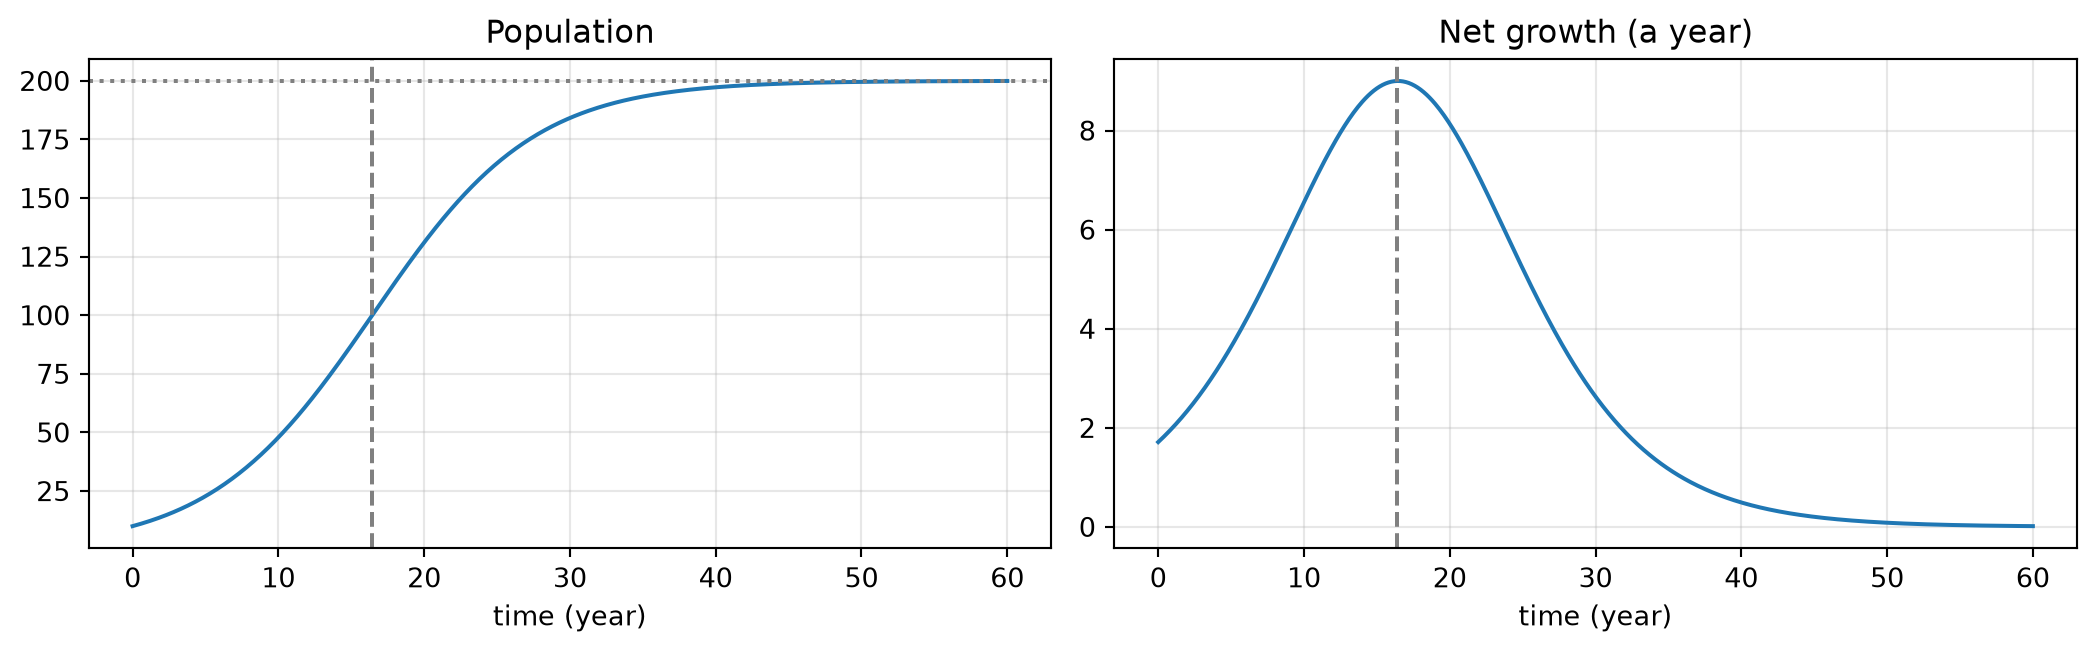

In [4]:
lg = lb.molecule("logistic").run()
net = lg["Growth"] - lg["Crowding deaths"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
lg["Population"].plot(ax=a1, title="Population"); a1.axhline(200, ls=":", c="grey")
net.plot(ax=a2, title="Net growth (a year)")
for ax in (a1, a2):
    ax.axvline(net.idxmax(), ls="--", c="grey"); ax.grid(alpha=0.3)
plt.tight_layout()
print(f"Net growth peaks in year {net.idxmax()} at {net.max():.1f} a year, "
      f"when the population is {lg.loc[net.idxmax(), 'Population']:.1f}")

Net growth peaks in year 16.4, when the population is 99.6, almost exactly half the carrying capacity. That point is the curve's **inflection point**: before it the curve bends upwards, after it downwards. It is where dominance shifts from the reinforcing loop to the balancing one. Every S-shaped curve has such a point, which is why the pattern tells you to look for a reinforcing loop that runs into a limit.

**Try it.** The **Diffusion** molecule (`diffusion`) has the same shape for a new product spreading through a market of 1,000. Compare its *Word-of-mouth* and *Ad-driven* presets: in which week is adoption fastest in each? Why does the ad-driven run hardly look S-shaped?

<details><summary>Show a worked answer</summary>

Adoption peaks in week 15.3 with word of mouth and in week 2.5 with advertising. With word of mouth (innovation 1%, imitation 18%), most adoption comes from adopters talking to non-adopters, a reinforcing loop that needs time to build up. With heavy advertising (innovation 4%, imitation 5%), people adopt on their own from the first week, so adoption is fastest almost at once and then falls as the market empties: the balancing loop dominates nearly from the start, and the curve looks like goal seeking.
</details>

Word-of-mouth : adoption fastest in week 15.3
Ad-driven     : adoption fastest in week 2.5


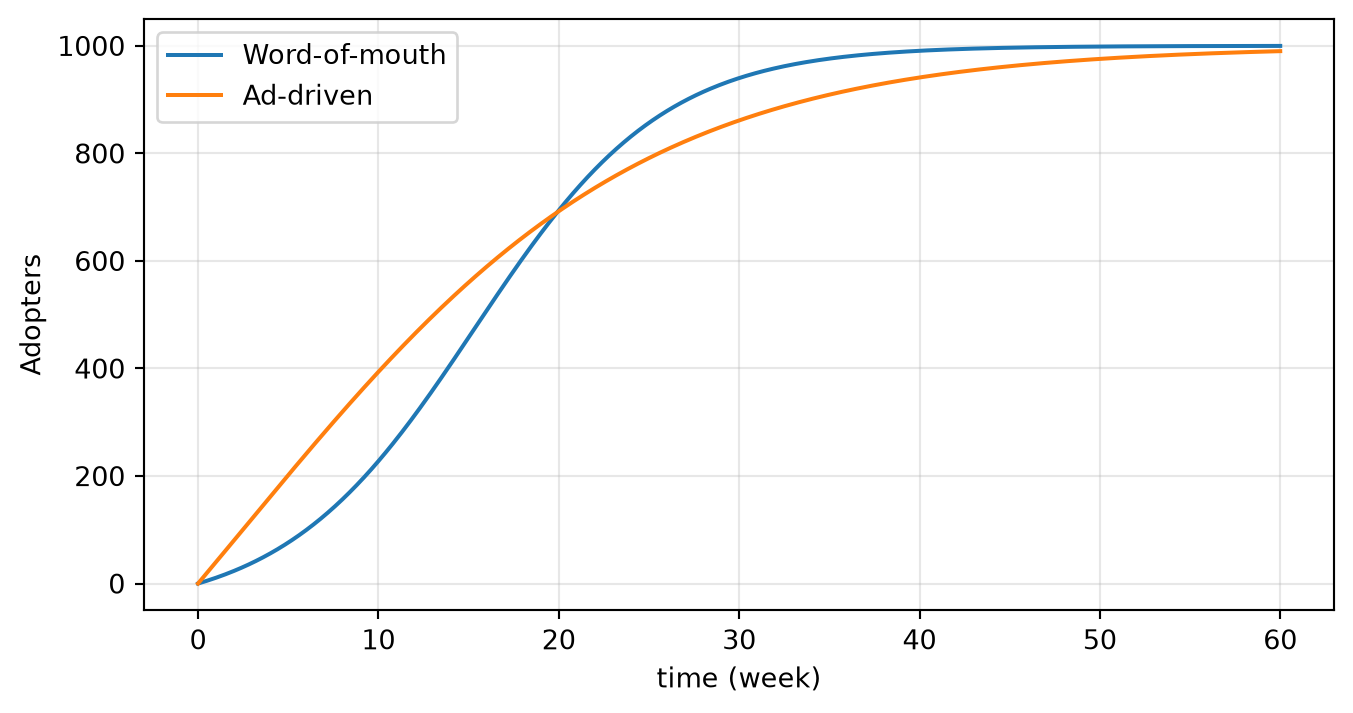

In [5]:
dif = lb.molecule("diffusion")
fig, ax = plt.subplots(figsize=(8, 4))
for name in ("Word-of-mouth", "Ad-driven"):
    run = dif.run(preset=name)
    run["Adopters"].plot(ax=ax, label=name)
    print(f"{name:14}: adoption fastest in week {run['Adoption'].idxmax()}")
ax.set_ylabel("Adopters"); ax.legend(); ax.grid(alpha=0.3)

## 3. Naming a pattern from the numbers

You can describe a pattern with two questions about the step-by-step changes in a series. Does the direction of change flip (once means overshoot, more than once means oscillation)? And if it never flips, where is the change biggest: at the end (accelerating, as in exponential growth), at the start (goal seeking), or in the middle (S-shaped)? A constant change is a straight line. The function below does exactly that.

In [6]:
def pattern(series):
    step = series.diff().dropna()               # change from one time step to the next
    size = step.abs()
    if size.max() < 1e-9:
        return "no change (equilibrium)"
    moving = step[size > 1e-3 * size.max()]      # ignore steps too small to see
    flips = (moving > 0).astype(int).diff().abs().sum()
    if flips >= 2:
        return "oscillation"
    if flips == 1:
        return "overshoot, then back"
    if size.max() - size.min() < 1e-6 * size.max():
        return "straight line"
    where = size.values.argmax() / (len(size) - 1)  # 0 = start of the run, 1 = end
    if where > 0.9:
        return "accelerating (exponential)"
    if where < 0.1:
        return "goal seeking"
    return "S-shaped"

runs = {
    "bathtub, Filling": lb.molecule("bathtub").run(preset="Filling")["Level"],
    "bathtub, Steady state": lb.molecule("bathtub").run(preset="Steady state")["Level"],
    "growth": growth,
    "closegap": goal,
    "decay": stock,
    "logistic": lg["Population"],
    "lowVisPipeline, ignores": swing,
    "lowVisPipeline, boom and bust": lv.run(preset="Boom and bust (slow supplier)")["Inventory"],
}
for name, series in runs.items():
    print(f"{name:30} {pattern(series)}")

bathtub, Filling               straight line
bathtub, Steady state          no change (equilibrium)
growth                         accelerating (exponential)
closegap                       goal seeking
decay                          goal seeking
logistic                       S-shaped
lowVisPipeline, ignores        oscillation
lowVisPipeline, boom and bust  oscillation


The function agrees with the eye on every run: a constant net flow gives a straight line, equal flows give equilibrium, and each molecule from sections 1 and 2 gets the name of its pattern. The boom-and-bust run, with a slower supplier and a more impatient buyer, oscillates too, with much bigger swings.

A pattern points to a structure, but it does not prove one. The next exercise shows why.

**Try it.** Run `pattern()` on the inventory from the *Tracks the pipeline* preset of `lowVisPipeline`, where the buyer counts every order on its way. The ordering rule is a pure goal-seeking rule. What does the function say, and why?

<details><summary>Show a worked answer</summary>

It says S-shaped. The inventory starts at 60 and barely moves at first (60.9 after two weeks), because the extra orders spend about six weeks with the supplier before they arrive. It rises fastest around week 6 and then eases into the target of 100. The decision rule is goal seeking, but the delay between ordering and receiving adds a slow start. So an S-shaped curve can come from a reinforcing loop meeting a limit, or from a balancing loop with a delay: to tell them apart, look at the structure, not only at the curve.
</details>

In [7]:
tracked = lv.run(preset="Tracks the pipeline")["Inventory"]
print("pattern:", pattern(tracked))
print("inventory in weeks 0, 2, 6, 20:", tracked.loc[[0.0, 2.0, 6.0, 20.0]].round(1).tolist())
print("rising fastest in week", tracked.diff().idxmax())

pattern: S-shaped
inventory in weeks 0, 2, 6, 20: [60.0, 60.9, 72.4, 96.6]
rising fastest in week 6.1


## Where next

- Back in the app: the [Patterns of behaviour and the structures behind them](https://waelrash1.github.io/loopbricks/#/learn/patterns) module has a gallery of the patterns and the structures behind each.
- Next notebook: [First-order feedback: growth, decay and goal seeking](https://waelrash1.github.io/loopbricks/#/learn/first-order) works out the exact maths of the single-loop patterns in section 1. [S-shaped growth](https://waelrash1.github.io/loopbricks/#/learn/s-shaped) and [Oscillation](https://waelrash1.github.io/loopbricks/#/learn/oscillation) go deeper into sections 2 and 3.
- In the [modelling process](https://waelrash1.github.io/loopbricks/#/learn/process) module, the pattern you want to explain is called the **reference mode**, and it is where every model starts.